# Glycan database — template → registration → PyTorch dataset

This notebook provides **three sequential steps**:

1. `write_registration_template("Man5")` creates `Man5/glycan.yaml` from COLVAR connectivity. **Fill in and verify all chemical `TODO` values before continuing.**
2. `register_glycan("Man5")` validates the chemistry and input files, writes `structures/Man5.json` and `Man5/fe_index.csv`, then updates `manifest.csv`.
3. `build_dataset()` reads **all registered glycans** from `manifest.csv` and writes one PyTorch `.pt` file. Run this step again after adding or changing registrations.

**Directory layout** (relative to `DATABASE_ROOT`):

```text
glycan_database/
├── manifest.csv                     # created/updated in step 2
├── structures/Man5.json             # created in step 2
└── Man5/
    ├── colvar.dat                   # required, or a discoverable COLVAR file
    ├── free_energy/                 # required: FE profile for each COLVAR torsion
    │   └── fes_phi1_2.dat           # example filename
    ├── glycan.yaml                 # created in step 1; complete manually
    ├── preprocessed.xtc            # required by registration, preprocessed externally
    ├── reference.pdb                # optional topology for residue inspection
    ├── conformer_states.csv        # optional in simplified dataset
    └── fe_index.csv                # created in step 2
```

**Required Python packages:** `numpy`, `pandas`, `PyYAML`, `torch`, `matplotlib`, `networkx`, `IPython`. `mdtraj` is optional for PDB inspection. This streamlined dataset stores canonical graph tensors, torsion histograms and interpolated FE profiles, and optional conformer labels. It **does not calculate SASA, ring puckering, or run GlyCONFORMER automatically**. Those are separate, optional scientific workflows.

**Scientific assumptions:** COLVAR and FE angles are in radians by default; histograms use 99 periodic bins over [−π, π), uniform frame weights, and FE curves are interpolated onto bin centers. Confirm these assumptions match your simulation and FE files. No training/test split or model training is performed here.

## 0. Settings and imports

Change only `DATABASE_ROOT` and (if needed) `GLYCAN_ID`.

In [1]:
from __future__ import annotations
import json, math, re, warnings
import yaml
from dataclasses import dataclass, asdict
from pathlib import Path
from collections import Counter, defaultdict
from typing import Any, Optional
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

In [2]:
DATABASE_ROOT = Path("../data/glycan_database")
GLYCAN_ID = "Man5"
DATASET_PATH = DATABASE_ROOT / "glycan_dataset.pt"

@dataclass
class BuilderConfig:
    database_root: str = str(DATABASE_ROOT)
    manifest_name: str = "manifest.csv"
    output_name: str = "glycan_dataset.pt"
    num_torsion_bins: int = 99
    torsion_min: float = -math.pi
    torsion_max: float = math.pi
    colvar_angle_unit: str = "radian"
    fe_angle_unit: str = "radian"
    sampling_mode: str = "uniform_no_reweighting_required"
    terminal_modifications_last: bool = True
    higher_acceptor_linkage_first: bool = True
    defer_terminal_root_side_branches: bool = True
    yaml_order_fallback: bool = True
    eps: float = 1e-12
    required_preprocessed_xtc_name: str = "preprocessed.xtc"
    glyconformer_auto_generate: bool = False
    glyconformer_output_file: str = "conformer_states.csv"
    glyconformer_separator_file: str = "separator.dat"
    glyconformer_omega_file: str = "omega_angles.dat"

cfg = BuilderConfig()
ROOT = DATABASE_ROOT
MANIFEST = ROOT / cfg.manifest_name
OUTPUT = DATASET_PATH
print("Database:", ROOT.resolve())
print("Dataset output:", OUTPUT.resolve())

Database: /home/niemann/Desktop/test_datatset_builder/data/glycan_database
Dataset output: /home/niemann/Desktop/test_datatset_builder/data/glycan_database/glycan_dataset.pt


## 1. Shared file discovery and chemistry helpers

Locate inputs, parse COLVAR torsions, and prepare canonical chemistry metadata.

In [3]:
TORSION_COL_RE = re.compile(r"^(phi|psi|omega)(\d+)_(\d+)$", re.IGNORECASE)
MANIFEST_COLUMNS = [
    "glycan_id", "structure_json", "colvar_file", "conformer_file",
    "fe_index_file", "trajectory_file", "topology_file", "weight_column"
]

In [4]:
def discover_one(folder, patterns, required=False, label="file"):
    """Return one discovered file. Fail on ambiguity rather than guessing."""
    folder = Path(folder)
    hits = []
    for pattern in patterns:
        hits.extend(p for p in folder.glob(pattern) if p.is_file())
    hits = sorted(set(hits))
    if len(hits) > 1:
        raise ValueError(f"{folder.name}: ambiguous {label}; found {[p.name for p in hits]}")
    if required and not hits:
        raise FileNotFoundError(f"{folder.name}: required {label} not found in {folder}")
    return hits[0] if hits else None

In [5]:
def required_preprocessed_trajectory(glycan_id):
    """Return ROOT/<glycan_id>/preprocessed.xtc and never fall back to any other XTC."""
    folder = ROOT / str(glycan_id)
    path = folder / cfg.required_preprocessed_xtc_name
    if not path.is_file():
        raise FileNotFoundError(
            f"{glycan_id}: required trajectory not found: {path}. "
            "Run the external trajectory-preprocessing notebook first. "
            "No original/clustered/centered/aligned XTC fallback is allowed."
        )
    return path

In [6]:
def discover_glycan_folder(glycan_id, folder=None, require_preprocessed=True):
    """Discover standard inputs without inferring chemical identity/linkage.

    If require_preprocessed=False, trajectory discovery is deliberately deferred.
    This is used while creating/editing glycan.yaml so a missing preprocessed.xtc
    cannot prevent YAML-template generation.
    """
    folder = Path(folder) if folder is not None else ROOT / str(glycan_id)
    if not folder.exists():
        raise FileNotFoundError(folder)

    colvar = discover_one(folder, ["colvar.dat", "COLVAR", "COLVAR.*", "colvar.*"], True, "COLVAR")
    conformer = discover_one(folder, [cfg.glyconformer_output_file], False, "conformer-state CSV")
    separator_file = discover_one(folder, [cfg.glyconformer_separator_file], False, "GlyCONFORMER separator metadata")
    omega_file = discover_one(folder, [cfg.glyconformer_omega_file], False, "GlyCONFORMER omega metadata")
    topology = discover_one(folder, ["reference*.pdb", "*.pdb"], False, "reference PDB")
    trajectory = (
        required_preprocessed_trajectory(glycan_id)
        if require_preprocessed
        else ((folder / cfg.required_preprocessed_xtc_name)
              if (folder / cfg.required_preprocessed_xtc_name).is_file() else None)
    )

    fe_dir = folder / "free_energy"
    if not fe_dir.is_dir():
        candidates = sorted(p for p in folder.iterdir() if p.is_dir() and p.name.lower() in {"fes", "fe", "freeenergy", "free_energy"})
        if len(candidates) == 1:
            fe_dir = candidates[0]
        elif len(candidates) > 1:
            raise ValueError(f"{glycan_id}: ambiguous FE directories: {[p.name for p in candidates]}")
        else:
            raise FileNotFoundError(f"{glycan_id}: free-energy directory not found")

    metadata = None
    for name in ["glycan.yaml", "glycan.yml", "glycan_metadata.yaml", "glycan_metadata.yml"]:
        p = folder / name
        if p.exists():
            metadata = p
            break

    return {
        "glycan_id": str(glycan_id), "folder": folder, "colvar": colvar,
        "conformer": conformer, "separator_file": separator_file, "omega_file": omega_file,
        "fe_dir": fe_dir, "topology": topology,
        "trajectory": trajectory, "metadata": metadata,
    }

In [7]:
def load_colvar(path):
    """
    Read a whitespace-separated COLVAR with a header:
      first non-comment line = column names
      subsequent lines       = numerical values
    Example columns: time phi1_2 psi1_2 ...
    """
    df = pd.read_csv(path, sep=r"\s+", comment="#")
    if "time" not in df.columns:
        raise ValueError(f"{path}: expected a header containing 'time'")
    return df

In [8]:
def parse_colvar_dihedrals(colvar_path):
    """Infer directed raw residue pairs and torsion names from COLVAR column names."""
    df = load_colvar(colvar_path)
    rows = []
    ignored = []
    for col in df.columns:
        if str(col) == "time":
            continue
        m = TORSION_COL_RE.fullmatch(str(col).strip())
        if m:
            torsion, parent, child = m.groups()
            rows.append({
                "colvar_column": str(col).strip(),
                "torsion_name": torsion.lower(),
                "parent": str(parent), "child": str(child),
                "edge_id": f"{parent}_{child}",
            })
        else:
            ignored.append(str(col))
    if not rows:
        raise ValueError(f"{colvar_path}: no columns matching phiN_M/psiN_M/omegaN_M")

    # Preserve first occurrence: COLVAR order remains useful within each edge.
    edge_order = []
    for r in rows:
        if r["edge_id"] not in edge_order:
            edge_order.append(r["edge_id"])
    return rows, edge_order, ignored

In [9]:
def infer_root_from_directed_edges(edge_rows):
    """Find the unique graph root from directed COLVAR edges, or return None if ambiguous."""
    parents = {r["parent"] for r in edge_rows}
    children = {r["child"] for r in edge_rows}
    candidates = sorted(parents - children)
    return candidates[0] if len(candidates) == 1 else None

In [10]:
def inspect_sasa_topology(glycan_id, folder=None):
    """Print COLVAR-derived graph nodes beside topology residues before YAML editing.

    This is inspection only: no node-to-residue mapping is guessed. The user should
    use the table to fill pdb_residues in glycan.yaml explicitly.
    """
    d = discover_glycan_folder(glycan_id, folder, require_preprocessed=False)
    rows, _, _ = parse_colvar_dihedrals(d["colvar"])

    nodes = []
    seen = set()
    for r in rows:
        for n in (r["parent"], r["child"]):
            if n not in seen:
                seen.add(n)
                nodes.append(n)

    print(f"\n=== SASA topology inspection: {glycan_id} ===")
    print("\nCOLVAR-derived graph nodes")
    display(pd.DataFrame({"raw_node_id": nodes}))

    if d["trajectory"] is None:
        print("No XTC discovered. SASA will remain optional/unavailable for this glycan.")
    else:
        print("XTC:", d["trajectory"].name)

    if d["topology"] is None:
        print("No PDB topology discovered. Add the topology matching the XTC before SASA calculation.")
        return {"graph_nodes": nodes, "topology_residues": None, "discovery": d}

    try:
        import mdtraj as md
    except ImportError as e:
        raise ImportError("MDTraj is required for topology inspection. Install with: pip install mdtraj") from e

    top = md.load(str(d["topology"])).topology
    residue_rows = []
    for res in top.residues:
        residue_rows.append({
            "topology_index": int(res.index),
            "resSeq": int(res.resSeq),
            "resName": str(res.name),
            "n_atoms": sum(1 for _ in res.atoms),
            "atom_names": ", ".join(str(a.name) for a in res.atoms),
        })
    residue_df = pd.DataFrame(residue_rows)

    print("Topology:", d["topology"].name)
    print("\nTopology residues (use resSeq values for pdb_residues)")
    display(residue_df)
    print("\nFill glycan.yaml explicitly as: raw graph node ID -> topology resSeq.")
    print("No mapping is inferred automatically.")

    return {"graph_nodes": nodes, "topology_residues": residue_df, "discovery": d}

## 2. Create the editable YAML template

Only the initial template is automated; chemical identities and linkage positions must be checked by the user.

In [11]:
def write_registration_template(glycan_id, folder=None, overwrite=False):
    """Create a starter glycan.yaml before requiring preprocessed.xtc."""
    d = discover_glycan_folder(glycan_id, folder, require_preprocessed=False)
    # Show trajectory/topology residue numbering BEFORE writing the YAML so the
    # pdb_residues mapping can be filled safely. This never guesses chemistry.
    inspect_sasa_topology(glycan_id, folder)
    rows, edge_order, ignored = parse_colvar_dihedrals(d["colvar"])
    nodes = []
    seen = set()
    for r in rows:
        for n in [r["parent"], r["child"]]:
            if n not in seen:
                seen.add(n); nodes.append(n)
    root = infer_root_from_directed_edges(rows)
    template = {
        "glycan_id": str(glycan_id),
        "root": root if root is not None else "TODO",
        "monosaccharides": {n: "TODO" for n in nodes},
        "linkages": {eid: "TODO" for eid in edge_order},
        "terminal_modifications": [],
        "pdb_residues": ({n: "TODO" for n in nodes} if d["topology"] is not None else {}),
        # Six ring atoms in the exact cyclic order used for Cremer–Pople coordinates.
        # Example for a pyranose may be ["O5","C1","C2","C3","C4","C5"],
        # but CHECK YOUR TOPOLOGY: the notebook never guesses this chemistry.
        "pucker_ring_atoms": ({n: ["TODO"] * 6 for n in nodes} if d["topology"] is not None else {}),
    }
    out = d["folder"] / "glycan.yaml"
    if out.exists() and not overwrite:
        print(f"Not overwriting existing {out}")
        return out
    out.write_text(yaml.safe_dump(template, sort_keys=False, allow_unicode=True))
    print(f"Wrote registration template: {out}")
    if ignored:
        print("Non-torsion COLVAR columns ignored:", ignored)
    return out

In [40]:
# STEP 1: Uncomment to create the template (will not overwrite existing YAML).
write_registration_template(GLYCAN_ID)


=== SASA topology inspection: Man5 ===

COLVAR-derived graph nodes


,raw_node_id
0,1
1,2
2,3
3,4
4,5
5,6
6,7


XTC: preprocessed.xtc
Topology: reference_rest-rect.pdb

Topology residues (use resSeq values for pdb_residues)


,topology_index,resSeq,resName,n_atoms,atom_names
0,0,1,ALA,11,"N, H, H2, CA, HA, CB, HB1, HB2, HB3, C, O"
1,1,2,ASN,13,"N, H, CA, HA, CB, HB3, HB2, CG, OD1, ND2, HD22..."
2,2,3,ALA,12,"N, H, CA, HA, CB, HB1, HB2, HB3, C, O, OXT, HT2B"
3,3,4,BGLC,27,"C1, H1, C5, H5, O5, C2, H2, N, HN, C, O, CT, H..."
4,4,5,BGLC,27,"C1, H1, C5, H5, O5, C2, H2, N, HN, C, O, CT, H..."
5,5,6,BMAN,20,"C1, H1, C5, H5, O5, C2, H2, O2, HO2, C3, H3, O..."
6,6,7,AMAN,20,"C1, H1, C5, H5, O5, C2, H2, O2, HO2, C3, H3, O..."
7,7,8,AMAN,22,"C1, H1, C5, H5, O5, C2, H2, O2, HO2, C3, H3, O..."
8,8,9,AMAN,22,"C1, H1, C5, H5, O5, C2, H2, O2, HO2, C3, H3, O..."
9,9,10,AMAN,22,"C1, H1, C5, H5, O5, C2, H2, O2, HO2, C3, H3, O..."



Fill glycan.yaml explicitly as: raw graph node ID -> topology resSeq.
No mapping is inferred automatically.
Not overwriting existing ../data/glycan_database/Man5/glycan.yaml


PosixPath('../data/glycan_database/Man5/glycan.yaml')

## 3. Register a glycan

Create the graph JSON and FE index, validate them, then update the manifest. Existing `conformer_states.csv` is checked when present; it is not generated here.

In [13]:
def load_registration_metadata(path):
    """Load the glycan YAML metadata as a mapping; return an empty mapping if missing."""
    if path is None or not Path(path).exists():
        return {}
    data = yaml.safe_load(Path(path).read_text()) or {}
    if not isinstance(data, dict):
        raise ValueError(f"{path}: YAML root must be a mapping")
    return data

In [14]:
def build_structure_from_discovery(discovery, metadata):
    """Combine COLVAR connectivity and user-supplied YAML chemistry into a validated structure and torsion records."""
    rows, edge_order, ignored = parse_colvar_dihedrals(discovery["colvar"])
    gid = str(metadata.get("glycan_id", discovery["glycan_id"]))
    monos = {str(k): str(v) for k, v in (metadata.get("monosaccharides") or {}).items()}
    linkages = {str(k): str(v) for k, v in (metadata.get("linkages") or {}).items()}
    pdb_res = {str(k): v for k, v in (metadata.get("pdb_residues") or {}).items()}
    pucker_ring_atoms = {str(k): v for k, v in (metadata.get("pucker_ring_atoms") or {}).items()}
    terminal = {str(x) for x in (metadata.get("terminal_modifications") or [])}

    nodes = []
    seen = set()
    for r in rows:
        for n in [r["parent"], r["child"]]:
            if n not in seen:
                seen.add(n); nodes.append(n)

    root = metadata.get("root")
    if root is None:
        root = infer_root_from_directed_edges(rows)
    root = None if root is None else str(root)

    missing_mono = [n for n in nodes if not monos.get(n) or monos.get(n) == "TODO"]
    missing_link = [e for e in edge_order if not linkages.get(e) or linkages.get(e) == "TODO"]
    if root in {None, "TODO"} or missing_mono or missing_link:
        problems = []
        if root in {None, "TODO"}: problems.append("root")
        if missing_mono: problems.append(f"monosaccharides for nodes {missing_mono}")
        if missing_link: problems.append(f"linkages for edges {missing_link}")
        raise ValueError(
            f"{gid}: registration chemistry incomplete: " + "; ".join(problems) +
            ". Fill glycan.yaml; chemistry is never guessed from torsion names."
        )

    # Preserve the verified monosaccharide insertion order from glycan.yaml.
    # This is stored explicitly as yaml_position and is the safety backup for
    # canonical graph ordering. All graph nodes must occur in monosaccharides:.
    yaml_node_order = [str(k) for k in monos.keys() if str(k) in seen]
    if set(yaml_node_order) != set(nodes):
        raise ValueError(
            f"{gid}: monosaccharides: keys must match all graph nodes exactly. "
            f"YAML={yaml_node_order}; graph={nodes}"
        )

    node_objs = []
    for yaml_position, n in enumerate(yaml_node_order):
        obj = {"id": n, "mono": monos[n], "terminal_modification": n in terminal,
               "yaml_position": int(yaml_position)}
        if n in pdb_res and pdb_res[n] not in {None, "", "TODO"}:
            obj["pdb_resid"] = int(pdb_res[n])
        ring = pucker_ring_atoms.get(n)
        if isinstance(ring, (list, tuple)) and len(ring) == 6 and all(str(x).strip().upper() != "TODO" for x in ring):
            obj["pucker_ring_atoms"] = [str(x).strip() for x in ring]
        node_objs.append(obj)

    edges = []
    pair_lookup = {}
    for r in rows:
        pair_lookup.setdefault(r["edge_id"], (r["parent"], r["child"]))
    for eid in edge_order:
        parent, child = pair_lookup[eid]
        edges.append({"id": eid, "parent": parent, "child": child, "linkage": linkages[eid]})

    return {"glycan_id": gid, "root_node": root, "nodes": node_objs, "edges": edges}, rows, ignored

In [15]:
def find_fe_for_colvar(fe_dir, colvar_column):
    """Match one torsion to one FE file; ambiguity is an error."""
    fe_dir = Path(fe_dir)
    preferred = [
        fe_dir / f"fes_{colvar_column}.dat",
        fe_dir / f"fes_{colvar_column}.txt",
        fe_dir / f"{colvar_column}.dat",
        fe_dir / f"{colvar_column}.txt",
    ]
    exact = [p for p in preferred if p.exists()]
    if len(exact) == 1:
        return exact[0]
    if len(exact) > 1:
        raise ValueError(f"Ambiguous FE profiles for {colvar_column}: {[p.name for p in exact]}")

    # Conservative fallback: filename stem must end in the exact COLVAR column.
    hits = []
    for p in fe_dir.iterdir():
        if p.is_file() and p.stem.lower().endswith(str(colvar_column).lower()):
            hits.append(p)
    hits = sorted(set(hits))
    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected exactly one FE profile for {colvar_column}; found {[p.name for p in hits]}"
        )
    return hits[0]

In [16]:
def make_fe_index_from_discovery(discovery, dihedral_rows):
    """Match each parsed COLVAR torsion with its free-energy profile and construct an FE-index table."""
    out = []
    for r in dihedral_rows:
        fe = find_fe_for_colvar(discovery["fe_dir"], r["colvar_column"])
        out.append({
            "edge_id": r["edge_id"], "torsion_name": r["torsion_name"],
            "colvar_column": r["colvar_column"],
            "fe_file": str(fe.relative_to(discovery["folder"])),
        })
    return pd.DataFrame(out)

In [17]:
LINK_RE = re.compile(r"([abAB])(\d+)-(\d+)")
def parse_linkage(s):
    m = LINK_RE.fullmatch(str(s).strip())
    if not m: return 0.0, 0.0, -1, -1
    a,d,acc = m.groups()
    return float(a.lower()=="a"), float(a.lower()=="b"), int(d), int(acc)

In [18]:
MONO_VOCAB = ["UNK","Glc","Gal","GlcNAc","GalNAc","Neu5Ac","Neu5Gc","Fuc","Man","Xyl","IdoA","GlcA"]
MONO_TO_ID = {x:i for i,x in enumerate(MONO_VOCAB)}
LINKAGE_VOCAB = ["UNK","a1-2","a1-3","a1-4","a1-6","a2-3","a2-6","a2-8","b1-2","b1-3","b1-4","b1-6"]
LINKAGE_TO_ID = {x:i for i,x in enumerate(LINKAGE_VOCAB)}

In [19]:
def load_structure(path):
    """Load a generated structure JSON into root, node lookup, and edge records."""
    o = json.loads(Path(path).read_text())
    nodes = {str(n["id"]): dict(n) for n in o["nodes"]}
    edges = [dict(e, id=str(e["id"]), parent=str(e["parent"]), child=str(e["child"])) for e in o["edges"]]
    return str(o.get("glycan_id", Path(path).stem)), str(o["root_node"]), nodes, edges

In [20]:
def canonicalize(glycan_id, root, nodes, edges):
    """Canonicalize a rooted glycan tree with a chemically meaningful DFS order.

    Primary automatic rule
    ----------------------
    1. Start at the root.
    2. At an ordinary branch point, traverse the child with the highest acceptor
       linkage number first (e.g. 1-6 before 1-3), then backtrack and continue.
    3. If the root has a normal continuing subtree plus one or more terminal
       one-node side branches, defer those root-attached leaves until the very
       end of the whole traversal. This makes a core Fuc attached to the first
       GlcNAc the final canonical node without hard-coding the monosaccharide.

    Safety backup
    -------------
    register_glycan() stores the verified insertion order from glycan.yaml as
    node['yaml_position']. If the automatic order disagrees with that complete
    YAML order and cfg.yaml_order_fallback is True, YAML order wins with a warning.
    """
    children = defaultdict(list)
    indeg = Counter()
    incoming = {}
    for e in edges:
        if e["parent"] not in nodes or e["child"] not in nodes:
            raise ValueError(f"{glycan_id}: edge {e['id']} references unknown node")
        children[e["parent"]].append(e)
        indeg[e["child"]] += 1
        incoming[e["child"]] = e

    if root not in nodes or indeg[root] != 0:
        raise ValueError(f"{glycan_id}: invalid root {root}")
    for nid in nodes:
        if nid != root and indeg[nid] != 1:
            raise ValueError(f"{glycan_id}: expected rooted acyclic tree; node {nid} indegree={indeg[nid]}")

    def subtree_signature(nid):
        parts = []
        for e in children.get(nid, []):
            parts.append((e["linkage"], nodes[e["child"]]["mono"], subtree_signature(e["child"])))
        return (nodes[nid]["mono"], tuple(sorted(parts, reverse=True)))

    def sort_key(e):
        child = nodes[e["child"]]
        alpha,beta,donor,acceptor = parse_linkage(e["linkage"])
        terminal = int(bool(child.get("terminal_modification", False))) if cfg.terminal_modifications_last else 0
        acc_rank = -acceptor if cfg.higher_acceptor_linkage_first else acceptor
        anomer_rank = 0 if alpha else (1 if beta else 2)
        return (terminal, acc_rank, -donor, anomer_rank,
                MONO_TO_ID.get(child["mono"],9999), child["mono"],
                repr(subtree_signature(e["child"])), e["id"])

    # Root-attached terminal leaves are a special *structural* case. We defer
    # them only when the root also has at least one continuing (non-leaf) child.
    # Thus no monosaccharide identity (Fuc or otherwise) is guessed.
    root_edges = list(children.get(root, []))
    deferred_root_edges = []
    if cfg.defer_terminal_root_side_branches and len(root_edges) > 1:
        continuing = [e for e in root_edges if len(children.get(e["child"], [])) > 0]
        if continuing:
            deferred_root_edges = [e for e in root_edges if len(children.get(e["child"], [])) == 0]

    auto_order, visited = [], set()
    def dfs(nid):
        if nid in visited:
            raise ValueError(f"{glycan_id}: cycle detected")
        visited.add(nid)
        auto_order.append(nid)
        es = list(children.get(nid, []))
        if nid == root and deferred_root_edges:
            deferred_ids = {e["id"] for e in deferred_root_edges}
            es = [e for e in es if e["id"] not in deferred_ids]
        for e in sorted(es, key=sort_key):
            dfs(e["child"])

    dfs(root)
    for e in sorted(deferred_root_edges, key=sort_key):
        dfs(e["child"])

    if len(visited) != len(nodes):
        raise ValueError(f"{glycan_id}: disconnected nodes {sorted(set(nodes)-visited)}")

    # Complete YAML order is available only for structures generated by v7.5+.
    yaml_positions = {nid: nodes[nid].get("yaml_position") for nid in nodes}
    have_yaml_order = all(isinstance(v, int) for v in yaml_positions.values())
    yaml_order = (sorted(nodes, key=lambda nid: yaml_positions[nid]) if have_yaml_order else None)

    node_order = list(auto_order)
    order_source = "automatic_graph_rule"
    if yaml_order is not None and auto_order != yaml_order:
        msg = (f"{glycan_id}: automatic canonical node order {auto_order} disagrees with "
               f"verified glycan.yaml order {yaml_order}.")
        if cfg.yaml_order_fallback:
            warnings.warn(msg + " Using glycan.yaml order as safety fallback.")
            node_order = list(yaml_order)
            order_source = "yaml_fallback_after_graph_disagreement"
        else:
            raise ValueError(msg + " YAML fallback is disabled.")
    elif yaml_order is not None:
        order_source = "automatic_graph_rule_verified_by_yaml"

    # In a rooted tree every non-root node has exactly one incoming edge. Ordering
    # physical edges by the canonical position of their child guarantees that edge
    # and torsion numbering stay synchronized with canonical node numbering.
    edge_order = [incoming[nid]["id"] for nid in node_order if nid != root]
    edge_by_id = {e["id"]: e for e in edges}

    return {
        "node_order": node_order,
        "automatic_node_order": auto_order,
        "yaml_node_order": yaml_order,
        "order_source": order_source,
        "edge_order": edge_order,
        "node_to_idx": {n:i for i,n in enumerate(node_order)},
        "edge_to_idx": {e:i for i,e in enumerate(edge_order)},
        "edges": [edge_by_id[e] for e in edge_order],
    }

In [21]:
def canonical_dihedral_index(fe_index_path,canon):
    """Sort FE-index rows by canonical edge order and create canonical dihedral definitions."""
    df=pd.read_csv(fe_index_path)
    req={"edge_id","torsion_name","colvar_column","fe_file"}
    if req-set(df.columns): raise ValueError(f"Missing FE-index columns: {sorted(req-set(df.columns))}")
    df=df.copy(); df["edge_id"]=df["edge_id"].astype(str)
    unknown=set(df.edge_id)-set(canon["edge_to_idx"])
    if unknown: raise ValueError(f"Unknown edge IDs in FE index: {sorted(unknown)}")
    df["_edge"]=df.edge_id.map(canon["edge_to_idx"])
    df["_within"]=df.groupby("edge_id").cumcount()
    df=df.sort_values(["_edge","_within"],kind="stable").reset_index(drop=True)
    defs=[]
    for di,row in df.iterrows():
        e=canon["edges"][int(row["_edge"])]
        defs.append({
            "dihedral_id":int(di),"physical_edge_id":int(row["_edge"]),
            "raw_edge_id":e["id"],"source_node":canon["node_to_idx"][e["parent"]],
            "target_node":canon["node_to_idx"][e["child"]],"linkage":e["linkage"],
            "torsion_name":str(row["torsion_name"]),"colvar_column":str(row["colvar_column"]),
            "fe_file":str(row["fe_file"])
        })
    return df,defs

In [22]:
def canonical_dihedral_names(defs):
    """Canonical per-dihedral names, using the COLVAR column names."""
    return [d["colvar_column"] for d in defs]

In [23]:
def conformer_state_columns(df):
    """Return physical dihedral columns, excluding branch-display separators."""
    return [c for c in df.columns if not str(c).lower().startswith("sep")]

In [24]:
def load_conformer_states(path):
    """Read structured per-frame GlyCONFORMER state assignments from CSV.

    Separator columns (sep1, sep2, ...) are retained here for provenance/QC,
    but are excluded later from the machine-learning conformer state vector.
    Unicode labels such as G₋, G₊, A₋, A₊ are preserved exactly.
    """
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.strip()
    if len(df) == 0:
        raise ValueError(f"No conformer-state rows: {path}")
    return df

In [25]:
def validate_conformer_dihedral_order(conformer_df, expected_names, glycan_id="glycan"):
    """Helper used by the registration workflow: validate_conformer_dihedral_order."""
    observed = conformer_state_columns(conformer_df)
    expected = list(expected_names)
    if observed != expected:
        raise ValueError(
            f"{glycan_id}: GlyCONFORMER dihedral order does not match canonical order.\n"
            f"Expected: {expected}\nObserved: {observed}"
        )
    print(f"✓ {glycan_id}: GlyCONFORMER dihedral order matches canonical order")
    return observed

In [26]:
def _relative_to_root(path):
    """Store file paths relative to the configured database root where possible."""
    if path is None:
        return ""
    p = Path(path)
    try:
        return str(p.relative_to(ROOT))
    except ValueError:
        return str(p)

In [27]:
def upsert_manifest_row(row, path=MANIFEST):
    """Insert or replace the glycan entry in manifest.csv while preserving other registrations."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        old = pd.read_csv(path)
        for c in MANIFEST_COLUMNS:
            if c not in old.columns: old[c] = ""
        old = old[MANIFEST_COLUMNS]
        old = old[old["glycan_id"].astype(str) != str(row["glycan_id"])]
        df = pd.concat([old, pd.DataFrame([row], columns=MANIFEST_COLUMNS)], ignore_index=True)
    else:
        df = pd.DataFrame([row], columns=MANIFEST_COLUMNS)
    df.to_csv(path, index=False)
    return df

In [28]:
def plot_canonical_glycan(
    structure,
    canon,
    figsize=(14, 10),
    horizontal_spacing=3.0,
    vertical_spacing=3.0,
):
    """Plot canonical glycan tree with clearly visible physical edges and linkage labels."""
    nodes = {str(n["id"]): n for n in structure["nodes"]}
    edges = {str(e["id"]): e for e in structure["edges"]}

    G = nx.DiGraph()

    for canonical_id, raw_id in enumerate(canon["node_order"]):
        raw_id = str(raw_id)
        G.add_node(
            raw_id,
            canonical_id=canonical_id,
            mono=nodes[raw_id]["mono"],
        )

    for canonical_edge_id, raw_edge_id in enumerate(canon["edge_order"]):
        raw_edge_id = str(raw_edge_id)
        e = edges[raw_edge_id]
        G.add_edge(
            str(e["parent"]),
            str(e["child"]),
            canonical_edge_id=canonical_edge_id,
            raw_edge_id=raw_edge_id,
            linkage=e["linkage"],
        )

    root = str(structure["root_node"])
    children = {n: list(G.successors(n)) for n in G.nodes}
    positions = {}
    next_x = [0]

    def assign_position(node, depth=0):
        cs = children[node]
        if not cs:
            x = next_x[0] * horizontal_spacing
            next_x[0] += 1
        else:
            for child in cs:
                assign_position(child, depth + 1)
            x = float(np.mean([positions[child][0] for child in cs]))
        positions[node] = (x, -depth * vertical_spacing)

    assign_position(root)

    fig, ax = plt.subplots(figsize=figsize)

    # Edges first; generous node spacing leaves each bond visibly exposed.
    nx.draw_networkx_edges(
        G, positions, ax=ax, arrows=False, width=2.5, node_size=1600
    )

    nx.draw_networkx_nodes(
        G, positions, ax=ax, node_size=1600, linewidths=1.5, edgecolors="black"
    )

    node_labels = {
        raw: (
            f'{G.nodes[raw]["mono"]}\n'
            f'node {G.nodes[raw]["canonical_id"]}\n'
            f'raw {raw}'
        )
        for raw in G.nodes
    }
    nx.draw_networkx_labels(
        G, positions, labels=node_labels, font_size=8, ax=ax
    )

    edge_labels = {
        (u, v): (
            f'{d["linkage"]}\n'
            f'edge {d["canonical_edge_id"]}\n'
            f'raw {d["raw_edge_id"]}'
        )
        for u, v, d in G.edges(data=True)
    }
    nx.draw_networkx_edge_labels(
        G,
        positions,
        edge_labels=edge_labels,
        font_size=8,
        rotate=False,
        label_pos=0.5,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.9,
            "pad": 0.5,
        },
        ax=ax,
    )

    ax.set_title(
        f'{structure["glycan_id"]} — canonical glycan graph',
        fontsize=14,
    )
    ax.margins(0.15)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [29]:
def visual_qc_from_structure_file(path):
    """Helper used by the registration workflow: visual_qc_from_structure_file."""
    structure = json.loads(Path(path).read_text())
    nodes = {str(n["id"]): dict(n) for n in structure["nodes"]}
    edges = [
        dict(e, id=str(e["id"]), parent=str(e["parent"]), child=str(e["child"]))
        for e in structure["edges"]
    ]
    canon = canonicalize(
        str(structure.get("glycan_id", Path(path).stem)),
        str(structure["root_node"]),
        nodes,
        edges,
    )
    plot_canonical_glycan(structure, canon)
    return canon

In [30]:
def register_glycan(glycan_id, folder=None, require_conformers=True,
                    plot_graph=True, overwrite_generated=True):
    """Semi-automatically register one glycan into the v5 database.

    Automation:
      * discover files
      * parse COLVAR torsions/connectivity
      * match FE files
      * write structure JSON from minimal chemistry YAML
      * write FE index
      * upsert manifest
      * validate canonicalization, FE/COLVAR mapping, conformer order/frame count
      * optionally plot canonical graph

    Chemistry (monosaccharides/linkages) is never guessed.
    """
    # YAML-FIRST workflow: discover everything needed to create the chemistry
    # template without requiring the externally preprocessed trajectory yet.
    d = discover_glycan_folder(glycan_id, folder, require_preprocessed=False)
    if d["metadata"] is None:
        template = write_registration_template(glycan_id, d["folder"], overwrite=False)
        raise FileNotFoundError(
            f"{glycan_id}: glycan.yaml was missing. A starter template was written to {template}. "
            "Fill the TODO chemistry fields, then rerun register_glycan(). "
            "The preprocessed.xtc requirement is checked only after this YAML step."
        )

    # YAML now exists. From this point onward the v7.6 strict trajectory policy
    # applies: only ROOT/<glycan_id>/preprocessed.xtc is accepted.
    d["trajectory"] = required_preprocessed_trajectory(glycan_id)

    meta = load_registration_metadata(d["metadata"])
    structure, dihedral_rows, ignored = build_structure_from_discovery(d, meta)
    gid = structure["glycan_id"]

    structure_path = ROOT / "structures" / f"{gid}.json"
    fe_index_path = d["folder"] / "fe_index.csv"
    structure_path.parent.mkdir(parents=True, exist_ok=True)
    if overwrite_generated or not structure_path.exists():
        structure_path.write_text(json.dumps(structure, indent=2, ensure_ascii=False))
    fe_index = make_fe_index_from_discovery(d, dihedral_rows)
    if overwrite_generated or not fe_index_path.exists():
        fe_index.to_csv(fe_index_path, index=False)

    # Resolve/generate structured conformer states. Existing CSVs are reused.
    if d["conformer"] is None and cfg.glyconformer_auto_generate:
        try:
            conf_path = generate_glyconformer_states(
                gid, folder=d["folder"], metadata=meta, overwrite=False
            )
            d["conformer"] = conf_path
        except ImportError:
            if require_conformers:
                raise ImportError(
                    f"{gid}: conformer_states.csv is missing and GlyCONFORMER is not importable in this kernel. "
                    "Run generate_glyconformer_states(...) in the glyco kernel, then rerun registration."
                )
        except FileNotFoundError as e:
            if require_conformers:
                raise
            warnings.warn(str(e))

    if require_conformers and d["conformer"] is None:
        raise FileNotFoundError(
            f"{gid}: conformer_states.csv not found and automatic GlyCONFORMER metadata were unavailable. "
            "Add separator.dat + omega_angles.dat, or a glyconformer: fallback block to glycan.yaml."
        )

    row = {
        "glycan_id": gid,
        "structure_json": _relative_to_root(structure_path),
        "colvar_file": _relative_to_root(d["colvar"]),
        "conformer_file": _relative_to_root(d["conformer"]),
        "fe_index_file": _relative_to_root(fe_index_path),
        "trajectory_file": _relative_to_root(d["trajectory"]),
        "topology_file": _relative_to_root(d["topology"]),
        "weight_column": "",
    }
    # Registration QC using the same canonical machinery as model building.
    _, root, nodes, edges = load_structure(structure_path)
    canon = canonicalize(gid, root, nodes, edges)
    _, defs = canonical_dihedral_index(fe_index_path, canon)
    expected = canonical_dihedral_names(defs)
    colvar = load_colvar(d["colvar"])
    missing_cols = [x for x in expected if x not in colvar.columns]
    if missing_cols:
        raise ValueError(f"{gid}: canonical dihedrals absent from COLVAR: {missing_cols}")

    if d["conformer"] is not None:
        cdf = load_conformer_states(d["conformer"])
        validate_conformer_dihedral_order(cdf, expected, gid)
        if len(cdf) != len(colvar):
            raise ValueError(f"{gid}: frame mismatch COLVAR={len(colvar)} conformers={len(cdf)}")

    print(f"\n=== Registered {gid} ===")
    print(f"✓ {len(nodes)} nodes; {len(edges)} physical edges; {len(defs)} dihedrals")
    print(f"✓ canonical node-order source: {canon['order_source']}")
    order_qc = pd.DataFrame([{
        "canonical_node": i,
        "raw_node": nid,
        "monosaccharide": nodes[nid]["mono"],
        "yaml_position": nodes[nid].get("yaml_position"),
    } for i, nid in enumerate(canon["node_order"])])
    display(order_qc)
    print(f"✓ {len(fe_index)} / {len(defs)} FE profiles mapped")
    if d["conformer"] is not None:
        print(f"✓ conformer columns/order + {len(colvar)} frame count validated")
    if ignored:
        print("Ignored non-torsion COLVAR columns:", ignored)
    print("✓ structure:", structure_path)
    manifest = upsert_manifest_row(row)
    print("✓ FE index:", fe_index_path)
    print("✓ manifest updated:", MANIFEST)
    display(manifest)
    if plot_graph:
        visual_qc_from_structure_file(structure_path)

    return {
        "discovery": d, "metadata": meta, "structure": structure,
        "structure_path": structure_path, "fe_index": fe_index,
        "fe_index_path": fe_index_path, "manifest_row": row,
        "canonical": canon, "dihedral_definitions": defs,
    }


=== Registered Man5 ===
✓ 7 nodes; 6 physical edges; 14 dihedrals
✓ canonical node-order source: automatic_graph_rule_verified_by_yaml


,canonical_node,raw_node,monosaccharide,yaml_position
0,0,1,GlcNAc,0
1,1,2,GlcNAc,1
2,2,3,Man,2
3,3,4,Man,3
4,4,5,Man,4
5,5,6,Man,5
6,6,7,Man,6


✓ 14 / 14 FE profiles mapped
✓ structure: ../data/glycan_database/structures/Man5.json
✓ FE index: ../data/glycan_database/Man5/fe_index.csv
✓ manifest updated: ../data/glycan_database/manifest.csv


,glycan_id,structure_json,colvar_file,conformer_file,fe_index_file,trajectory_file,topology_file,weight_column
0,Man5,structures/Man5.json,Man5/colvar.dat,,Man5/fe_index.csv,Man5/preprocessed.xtc,Man5/reference_rest-rect.pdb,


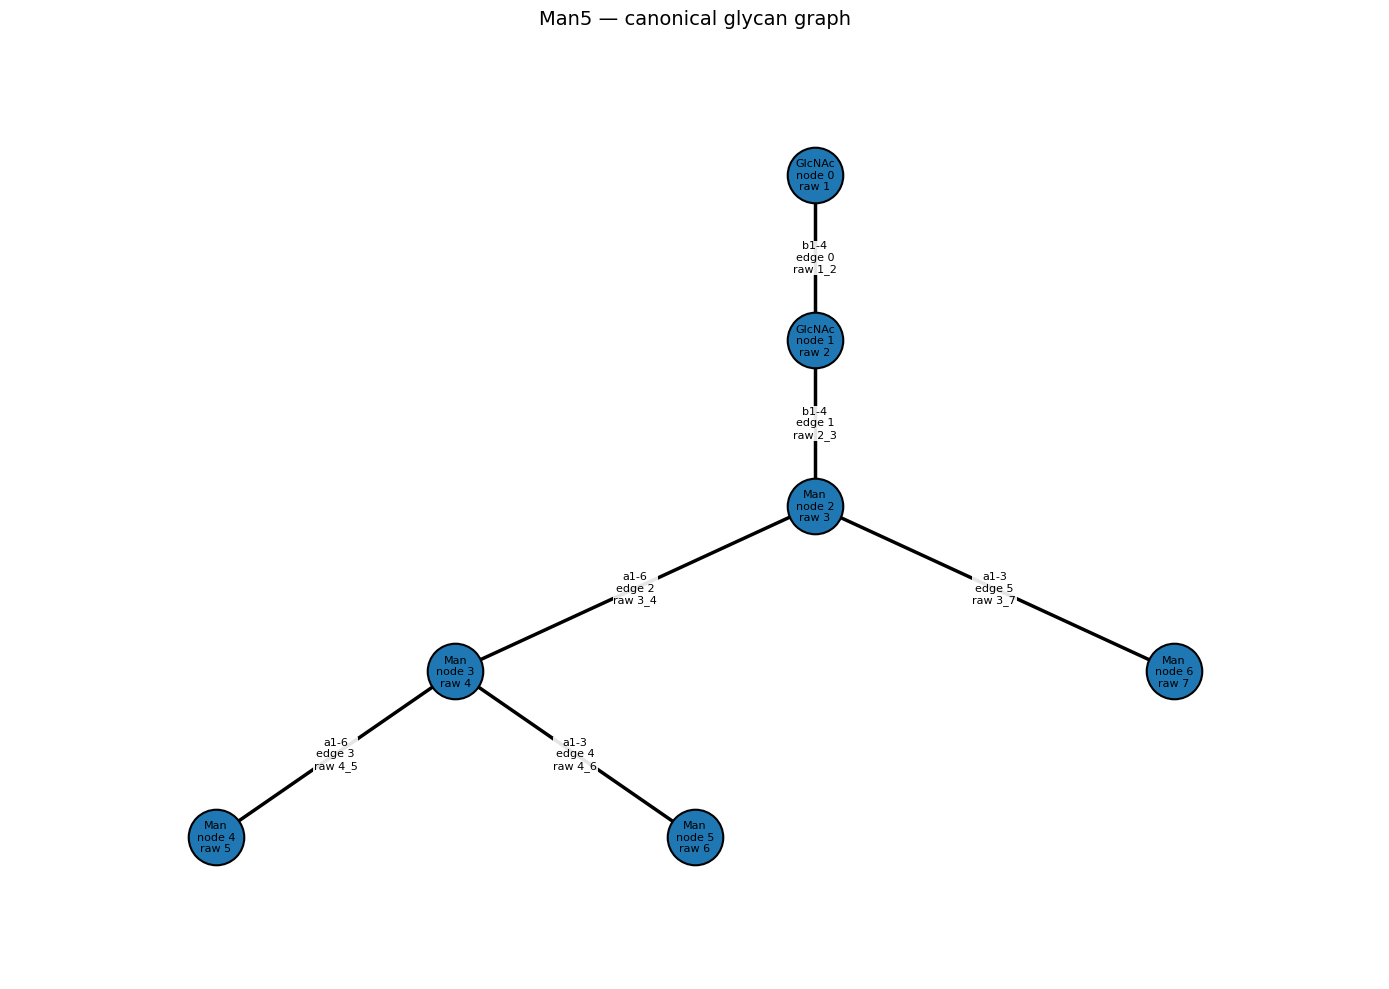

{'discovery': {'glycan_id': 'Man5',
  'folder': PosixPath('../data/glycan_database/Man5'),
  'colvar': PosixPath('../data/glycan_database/Man5/colvar.dat'),
  'conformer': None,
  'separator_file': PosixPath('../data/glycan_database/Man5/separator.dat'),
  'omega_file': PosixPath('../data/glycan_database/Man5/omega_angles.dat'),
  'fe_dir': PosixPath('../data/glycan_database/Man5/free_energy'),
  'topology': PosixPath('../data/glycan_database/Man5/reference_rest-rect.pdb'),
  'trajectory': PosixPath('../data/glycan_database/Man5/preprocessed.xtc'),
  'metadata': PosixPath('../data/glycan_database/Man5/glycan.yaml')},
 'metadata': {'glycan_id': 'Man5',
  'root': '1',
  'monosaccharides': {'1': 'GlcNAc',
   '2': 'GlcNAc',
   '3': 'Man',
   '4': 'Man',
   '5': 'Man',
   '6': 'Man',
   '7': 'Man'},
  'linkages': {'1_2': 'b1-4',
   '2_3': 'b1-4',
   '3_4': 'a1-6',
   '4_5': 'a1-6',
   '4_6': 'a1-3',
   '3_7': 'a1-3'},
  'terminal_modifications': [],
  'pdb_residues': {'1': 4, '2': 5, '3': 6

In [41]:
# STEP 2: Run after filling glycan.yaml and adding preprocessed.xtc.
register_glycan(GLYCAN_ID, require_conformers=False, plot_graph=True)

## 4. Build and save the combined `.pt` dataset

All registered glycans are included. Conformer labels are stored if available; missing conformers do not prevent dataset construction. The saved file contains standard Python containers and PyTorch tensors.

In [32]:
def prepare_manifest(manifest_path=MANIFEST):
    m = pd.read_csv(manifest_path)
    req = {"glycan_id", "structure_json", "colvar_file", "conformer_file", "fe_index_file"}
    missing = req - set(m.columns)
    if missing:
        raise ValueError(f"Manifest missing {sorted(missing)}")
    if m.glycan_id.astype(str).duplicated().any():
        raise ValueError("Duplicate glycan_id in manifest")
    return m

In [33]:
def resolve(base, value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    s = str(value).strip()
    if not s or s.lower() == "nan":
        return None
    p = Path(s)
    return p if p.is_absolute() else Path(base) / p

In [34]:
def mono_charge(m):
    return -1.0 if m in {"Neu5Ac","Neu5Gc","GlcA","IdoA"} else 0.0
def mono_carboxyl(m):
    return float(m in {"Neu5Ac","Neu5Gc","GlcA","IdoA"})
def mono_nacetyl(m):
    return float(m in {"GlcNAc","GalNAc","Neu5Ac"})
def mono_sulfate(m):
    return 0.0  # extend vocabulary/descriptor when sulfated residues are added

In [35]:
def graph_arrays(nodes, canon):
    M = len(canon["node_order"])
    degree=np.zeros(M,np.float32); indeg=np.zeros(M,np.float32); outdeg=np.zeros(M,np.float32)
    src=[]; dst=[]; linkage_ids=[]; edge_float=[]; physical_edge_id=[]
    physical_linkage_ids=[]; physical_edge_float=[]

    for ei,e in enumerate(canon["edges"]):
        u=canon["node_to_idx"][e["parent"]]; v=canon["node_to_idx"][e["child"]]
        degree[u]+=1; degree[v]+=1; outdeg[u]+=1; indeg[v]+=1
        a,b,d,acc=parse_linkage(e["linkage"])
        base=np.array([a,b,d/9 if d>=0 else 0,acc/9 if acc>=0 else 0],np.float32)
        lid=LINKAGE_TO_ID.get(e["linkage"],0)
        physical_linkage_ids.append(lid); physical_edge_float.append(base)
        for s,t,direction in [(u,v,1.0),(v,u,-1.0)]:
            src.append(s); dst.append(t); linkage_ids.append(lid)
            edge_float.append(np.r_[base,direction].astype(np.float32)); physical_edge_id.append(ei)

    node_float=[]; mono_ids=[]
    for i,nid in enumerate(canon["node_order"]):
        n=nodes[nid]; m=n["mono"]; mono_ids.append(MONO_TO_ID.get(m,0))
        node_float.append([
            mono_carboxyl(m), mono_charge(m), mono_sulfate(m), mono_nacetyl(m),
            degree[i]/4, indeg[i]/4, outdeg[i]/4,
            float(degree[i]<=1), float(outdeg[i]>1)
        ])

    return {
        "mono_ids":torch.tensor(mono_ids,dtype=torch.long),
        "node_float":torch.tensor(np.asarray(node_float),dtype=torch.float32),
        "edge_index":torch.tensor([src,dst],dtype=torch.long),
        "linkage_ids":torch.tensor(linkage_ids,dtype=torch.long),
        "edge_float":torch.tensor(np.asarray(edge_float),dtype=torch.float32),
        "physical_edge_id":torch.tensor(physical_edge_id,dtype=torch.long),
        "physical_linkage_ids":torch.tensor(physical_linkage_ids,dtype=torch.long),
        "physical_edge_float":torch.tensor(np.asarray(physical_edge_float),dtype=torch.float32),
    }

In [36]:
def _angle_radians(values, unit):
    """Convert angle arrays to radians; reject unknown angle units."""
    values = np.asarray(values, dtype=float)
    if unit == "radian":
        return values
    if unit == "degree":
        return np.deg2rad(values)
    raise ValueError(f"Unknown angle unit: {unit}")


def _torsion_grid():
    """Return periodic histogram edges and bin centers in radians."""
    edges = np.linspace(cfg.torsion_min, cfg.torsion_max, cfg.num_torsion_bins + 1)
    return edges, (edges[:-1] + edges[1:]) / 2


def _histogram(values):
    """Create a normalized periodic torsion histogram using uniform frame weights."""
    edges, _ = _torsion_grid()
    angles = _angle_radians(values, cfg.colvar_angle_unit)
    angles = (angles - edges[0]) % (2 * np.pi) + edges[0]
    hist, _ = np.histogram(angles, bins=edges)
    hist = hist.astype(float) + cfg.eps
    return torch.tensor(hist / hist.sum(), dtype=torch.float32)


def _fe_on_grid(path):
    """Read a two-column FE profile and interpolate it periodically onto torsion bin centers.

    Assumes column 1 is angle and column 2 is FE (same energy units across glycans).
    """
    data = np.loadtxt(path, comments="#", usecols=(0, 1), ndmin=2)
    if data.shape[0] < 2:
        raise ValueError(f"FE profile requires >= 2 samples: {path}")
    x = _angle_radians(data[:, 0], cfg.fe_angle_unit)
    y = np.asarray(data[:, 1], dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) < 2:
        raise ValueError(f"Not enough finite FE samples: {path}")
    x = (x + np.pi) % (2 * np.pi) - np.pi
    order = np.argsort(x)
    x, y = x[order], y[order]
    x, unique_idx = np.unique(x, return_index=True)
    y = y[unique_idx]
    if len(x) < 2:
        raise ValueError(f"FE angles collapse to one unique point: {path}")
    _, centers = _torsion_grid()
    interpolated = np.interp(centers, np.r_[x[-1]-2*np.pi, x, x[0]+2*np.pi],
                             np.r_[y[-1], y, y[0]])
    interpolated -= interpolated.min()
    return torch.tensor(interpolated, dtype=torch.float32)


def build_one_glycan(row):
    """Convert one manifest entry into canonical graph and torsion tensors."""
    gid = str(row["glycan_id"])
    structure_path = resolve(ROOT, row["structure_json"])
    colvar_path = resolve(ROOT, row["colvar_file"])
    fe_index_path = resolve(ROOT, row["fe_index_file"])
    _, root, nodes, edges = load_structure(structure_path)
    canon = canonicalize(gid, root, nodes, edges)
    graph = graph_arrays(nodes, canon)
    _, defs = canonical_dihedral_index(fe_index_path, canon)
    colvar = load_colvar(colvar_path)
    histograms, energies = [], []
    for definition in defs:
        name = definition["colvar_column"]
        if name not in colvar.columns:
            raise ValueError(f"{gid}: missing COLVAR column {name}")
        histograms.append(_histogram(colvar[name].to_numpy(float)))
        energies.append(_fe_on_grid(resolve(fe_index_path.parent, definition["fe_file"])))
    if not histograms:
        raise ValueError(f"{gid}: no torsions found")
    record = {
        "glycan_id": gid,
        **graph,
        "canonical_nodes": canon["node_order"],
        "dihedral_definitions": defs,
        "torsion_histograms": torch.stack(histograms),
        "torsion_free_energies": torch.stack(energies),
        "n_frames": len(colvar),
        "conformer_states": None,
    }
    conformer_path = resolve(ROOT, row.get("conformer_file"))
    if conformer_path is not None and conformer_path.is_file():
        states = load_conformer_states(conformer_path)
        validate_conformer_dihedral_order(states, canonical_dihedral_names(defs), gid)
        if len(states) != len(colvar):
            raise ValueError(f"{gid}: conformer/COLVAR frame counts differ")
        record["conformer_states"] = states.to_dict(orient="list")
    return record


def build_dataset(manifest_path=MANIFEST, output_path=OUTPUT):
    """Build all registered glycans and save a combined PyTorch .pt file."""
    manifest = prepare_manifest(manifest_path)
    if manifest.empty:
        raise ValueError("Manifest has no registered glycans")
    records = [build_one_glycan(row) for _, row in manifest.iterrows()]
    edges, centers = _torsion_grid()
    dataset = {
        "format_version": "glycan_registration_simple_v1",
        "glycans": records,
        "mono_vocab": MONO_VOCAB,
        "linkage_vocab": LINKAGE_VOCAB,
        "torsion_grid_edges": torch.tensor(edges, dtype=torch.float32),
        "torsion_grid_centers": torch.tensor(centers, dtype=torch.float32),
        "settings": {"colvar_angle_unit": cfg.colvar_angle_unit,
                     "fe_angle_unit": cfg.fe_angle_unit,
                     "fe_units": "unchanged from input FE profiles",
                     "frame_weights": "uniform"},
    }
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(dataset, output_path)
    print(f"Saved {len(records)} glycans to {output_path.resolve()}")
    return dataset

In [42]:
# STEP 3: Uncomment to build and save the combined .pt file.
dataset = build_dataset()

Saved 1 glycans to /home/niemann/Desktop/test_datatset_builder/data/glycan_database/glycan_dataset.pt


## 5. Inspect the saved dataset

Only load `.pt` files you trust. This notebook writes tensors and ordinary Python containers, compatible with `weights_only=True`.

In [43]:
# Uncomment after STEP 3:
loaded = torch.load(DATASET_PATH, map_location="cpu", weights_only=True)
print("Glycans:", [item["glycan_id"] for item in loaded["glycans"]])
man5 = next(item for item in loaded["glycans"] if item["glycan_id"] == GLYCAN_ID)
print("Stored fields:", list(man5))
print("Torsion histogram shape:", man5["torsion_histograms"].shape)

Glycans: ['Man5']
Stored fields: ['glycan_id', 'mono_ids', 'node_float', 'edge_index', 'linkage_ids', 'edge_float', 'physical_edge_id', 'physical_linkage_ids', 'physical_edge_float', 'canonical_nodes', 'dihedral_definitions', 'torsion_histograms', 'torsion_free_energies', 'n_frames', 'conformer_states']
Torsion histogram shape: torch.Size([14, 99])
